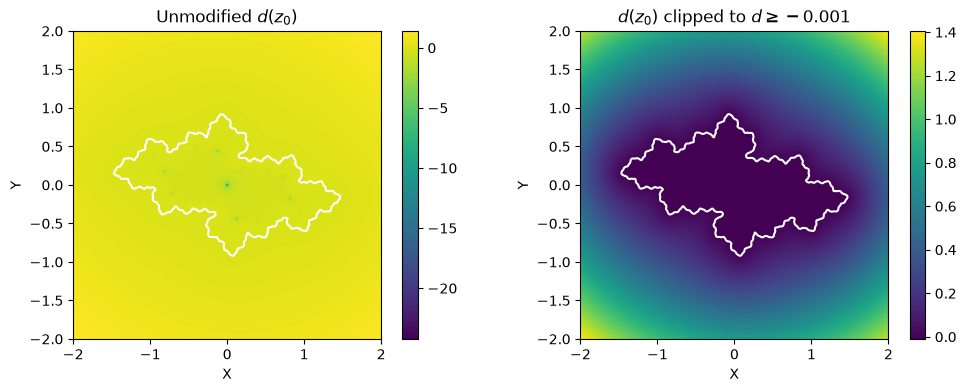

In [ ]:
# Plot a 2D slice of a julia SDF, with and without the flooring
from fractal_printer.mesh import fractal_sdfs as fs, mesh_generation as mg
import numpy as np
import sdf
import matplotlib.pyplot as plt
from importlib import reload
from fractal_printer.paths import REPO_ROOT

settings = {
    "coefficients": [
        [-0.639, 0.286, 0.0, 0],
        [0, 0, 0, 0],
        [1.0, 0, 0, 0]
    ],
    "power": 2,
    "bailout": 10000,
    "slice": 0.0,
    "offset": 0.01,
    "iterations": 10
}

reload(fs)
fig, axes = plt.subplots(1,2, figsize=(12,4))
for ax, interior_epsilon in zip(axes,[-100,-1e-3]):

    julia = fs.polynomial_julia_sdf(interior_epsilon=interior_epsilon,**settings)
    a, extent, _ = sdf.core.sample_slice(julia, z=0, bounds = ((-2,-2,-2),(2,2,2)))
    image = ax.imshow(a.T, extent=extent, origin = "lower")

    contour = ax.contour(
        np.linspace(extent[0],extent[1],a.shape[0]), 
        np.linspace(extent[2],extent[3], a.shape[1]), 
        a.T, 
        levels=[0], colors=["w"])
    fig.colorbar(image)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

axes[0].set_title("Unmodified $d(z_0)$")
axes[1].set_title(r"$d(z_0)$ clipped to $d\geq-0.001$")

fig.savefig(REPO_ROOT / "docs" / "images" / "inner_sdf_floor.png")

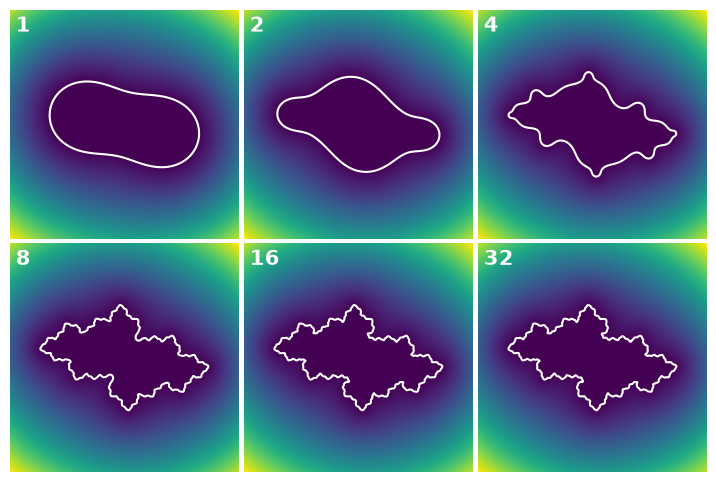

In [50]:
# Plot the effect of increasing iteration count
settings = {
    "coefficients": [
        [-0.639, 0.286, 0, 0],
        [0, 0, 0, 0],
        [1.0, 0, 0, 0],
    ],
    "power": 2,
    "bailout": 10000,
    "slice": 0.0,
    "offset": 0.01,
}

iterations = [2**n for n in range(6)]
fig, axes = plt.subplots(2,3, figsize=(9,6), sharex=True, sharey=True, gridspec_kw={"wspace":0.02, "hspace":0.02})


for ax, n in zip(axes.flatten(),iterations):
    julia = fs.polynomial_julia_sdf(iterations = n, **settings)
    a, extent, _ = sdf.core.sample_slice(julia, z=0, bounds = ((-2,-2,-2),(2,2,2)))
    image = ax.imshow(a.T, extent=extent, origin = "lower", aspect="equal")

    contour = ax.contour(
        np.linspace(extent[0],extent[1],a.shape[0]), 
        np.linspace(extent[2],extent[3], a.shape[1]), 
        a.T, 
        levels=[0], colors=["w"])

    ax.text(-1.9, 1.9, n, color="w", verticalalignment="top", weight="bold", size=15)
    ax.set_axis_off()

fig.savefig(REPO_ROOT / "docs" / "images" / "iteration_count.png")
